In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("Student_Performance_Prediction.csv")

# Display first five rows
print(df.head())

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Number of samples
print("\nNumber of samples:", df.shape[0])

# Number of features
print("Number of features:", df.shape[1] - 1)

# Target variable
print("Target variable: Final_Score")

   Study_Hours  Attendance_Percent  Practice_Tests  Sleep_Hours  \
0          3.2                83.7             2.3          6.5   
1          7.9                93.8             6.4          6.3   
2          4.1                97.4             4.4          5.4   
3          6.3                75.1             5.3          5.7   
4          2.1                85.1             2.0          7.1   

   Assignments_Completed  Screen_Time_Hours  Final_Score  
0                    3.2                5.7        60.31  
1                    6.9                6.8        80.57  
2                    5.8                6.7        68.77  
3                    8.6                4.9        74.02  
4                    9.4                4.9        61.62  

Column Names:
['Study_Hours', 'Attendance_Percent', 'Practice_Tests', 'Sleep_Hours', 'Assignments_Completed', 'Screen_Time_Hours', 'Final_Score']

Number of samples: 500
Number of features: 6
Target variable: Final_Score


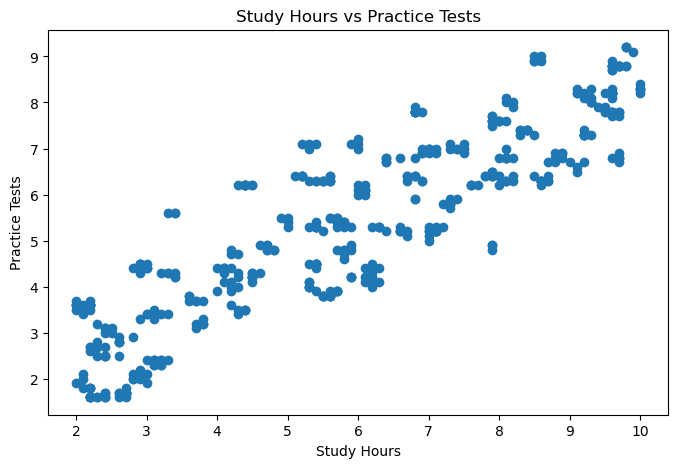

In [34]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Study_Hours"],
            df["Practice_Tests"])

plt.xlabel("Study Hours")
plt.ylabel("Practice Tests")
plt.title("Study Hours vs Practice Tests")

plt.show()

In [35]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate Pearson correlation
correlation_matrix = numeric_df.corr(method="pearson")

print(correlation_matrix)

                       Study_Hours  Attendance_Percent  Practice_Tests  \
Study_Hours               1.000000            0.026510        0.886156   
Attendance_Percent        0.026510            1.000000        0.043830   
Practice_Tests            0.886156            0.043830        1.000000   
Sleep_Hours               0.147746           -0.128525        0.149766   
Assignments_Completed    -0.027034           -0.036811        0.044144   
Screen_Time_Hours        -0.155519            0.087211       -0.105349   
Final_Score               0.878533            0.154457        0.885623   

                       Sleep_Hours  Assignments_Completed  Screen_Time_Hours  \
Study_Hours               0.147746              -0.027034          -0.155519   
Attendance_Percent       -0.128525              -0.036811           0.087211   
Practice_Tests            0.149766               0.044144          -0.105349   
Sleep_Hours               1.000000               0.161441          -0.249048   
Assignm

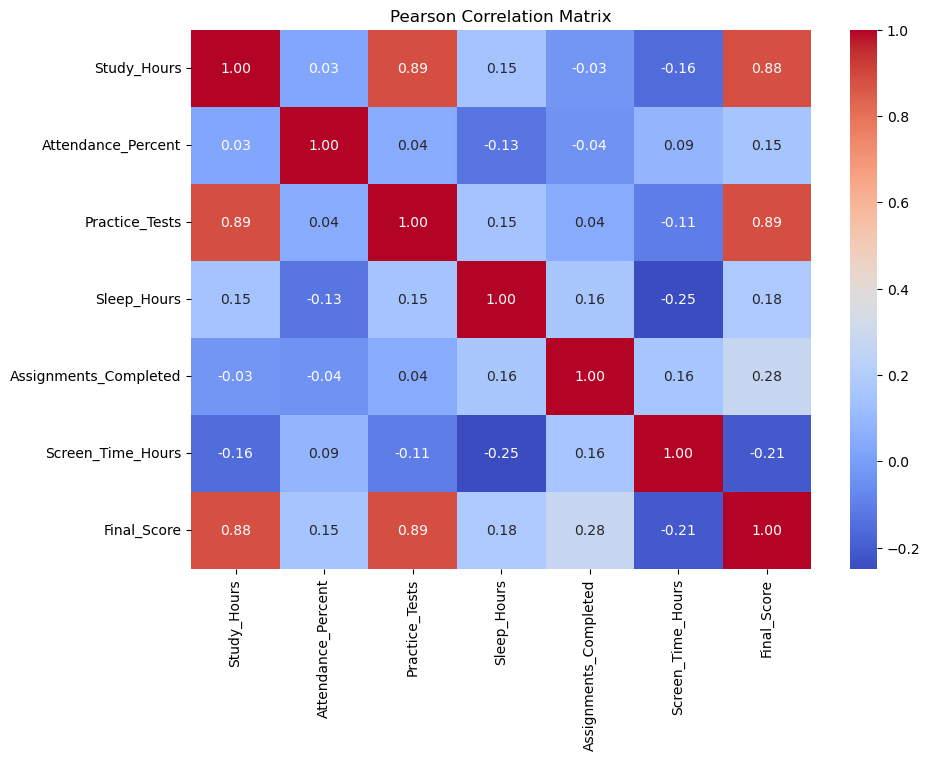

In [36]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Pearson Correlation Matrix")
plt.show()

In [37]:
target_corr = correlation_matrix["Final_Score"].drop("Final_Score")

print(target_corr)

Study_Hours              0.878533
Attendance_Percent       0.154457
Practice_Tests           0.885623
Sleep_Hours              0.178447
Assignments_Completed    0.277262
Screen_Time_Hours       -0.207730
Name: Final_Score, dtype: float64


In [38]:
ranking = target_corr.abs().sort_values(ascending=False)

print("Feature ranking based on absolute correlation:")
print(ranking)

Feature ranking based on absolute correlation:
Practice_Tests           0.885623
Study_Hours              0.878533
Assignments_Completed    0.277262
Screen_Time_Hours        0.207730
Sleep_Hours              0.178447
Attendance_Percent       0.154457
Name: Final_Score, dtype: float64


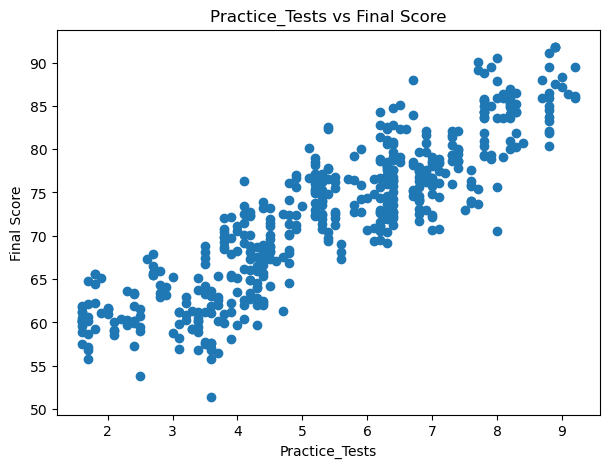

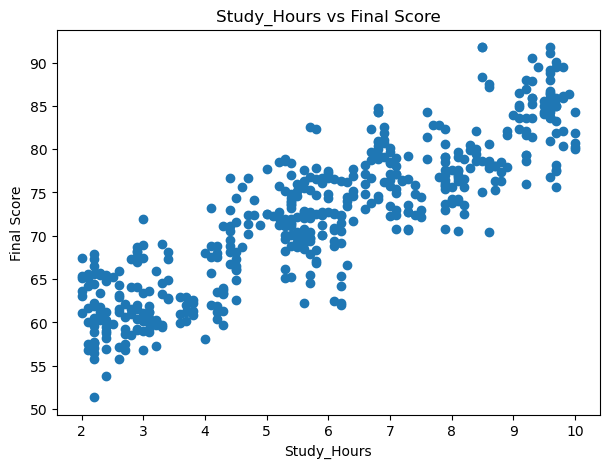

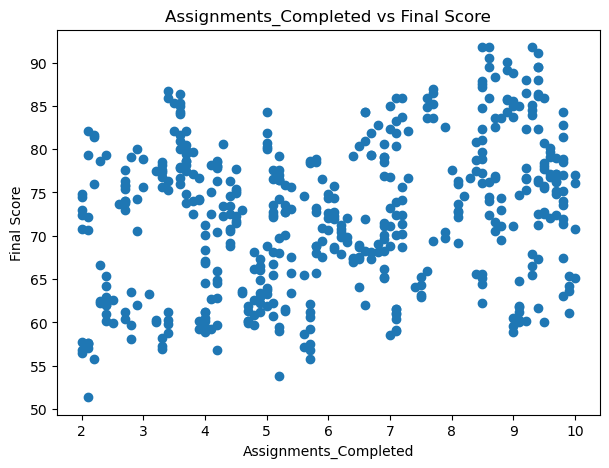

In [39]:
top_features = [
    "Practice_Tests",
    "Study_Hours",
    "Assignments_Completed"
]

for feature in top_features:

    plt.figure(figsize=(7, 5))

    plt.scatter(
        df[feature],
        df["Final_Score"]
    )

    plt.xlabel(feature)
    plt.ylabel("Final Score")
    plt.title(f"{feature} vs Final Score")

    plt.show()

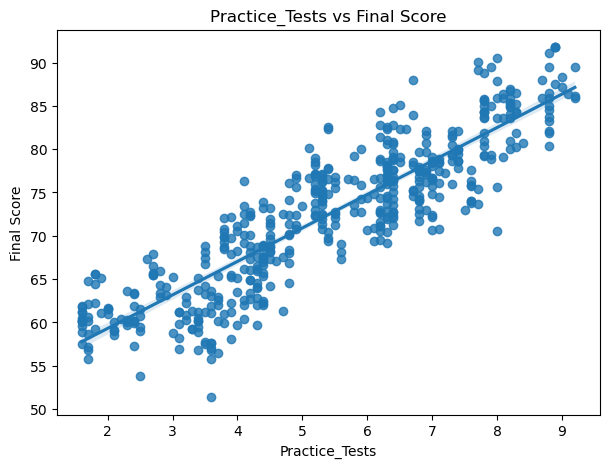

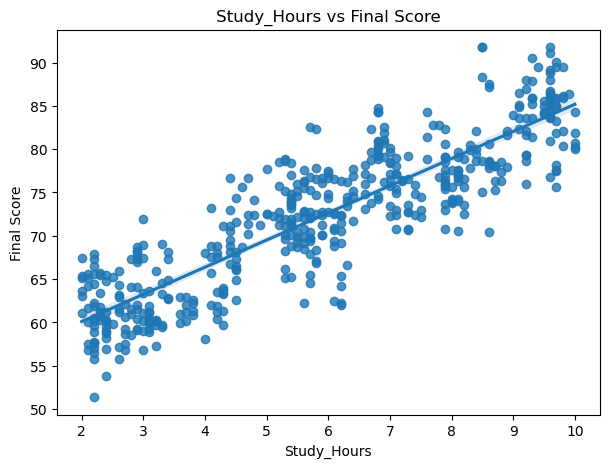

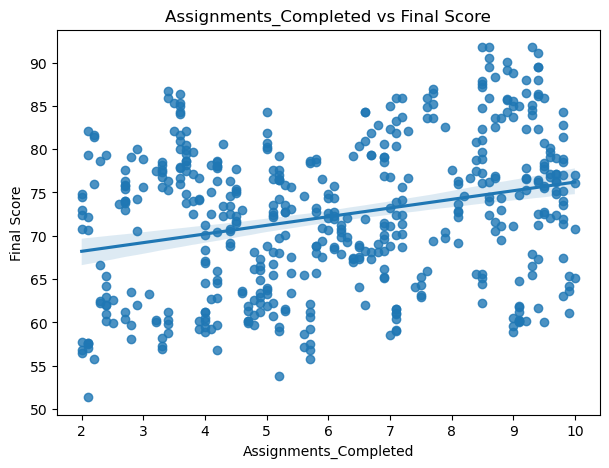

In [40]:
top_features = [
    "Practice_Tests",
    "Study_Hours",
    "Assignments_Completed"
]

for feature in top_features:

    plt.figure(figsize=(7, 5))

    sns.regplot(
        x=df[feature],
        y=df["Final_Score"]
    )

    plt.xlabel(feature)
    plt.ylabel("Final Score")
    plt.title(f"{feature} vs Final Score")

    plt.show()

In [41]:
# Question 2

import pandas as pd

# Load dataset
df = pd.read_csv("Student_Performance_Prediction.csv")

# Target variable
target = "Final_Score"

# Get feature columns
feature_cols = [
    col for col in df.select_dtypes(include="number").columns
    if col != target
]

In [42]:
# --------------------------------------------------
# (a) Find highly correlated feature pairs
# --------------------------------------------------

corr_matrix = df[feature_cols + [target]].corr()

high_corr_pairs = []

for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):

        feature1 = feature_cols[i]
        feature2 = feature_cols[j]

        r = corr_matrix.loc[feature1, feature2]

        if abs(r) >= 0.70:
            high_corr_pairs.append(
                (feature1, feature2, r)
            )

print("Highly correlated feature pairs:")

for feature1, feature2, r in high_corr_pairs:
    print(
        feature1,
        "and",
        feature2,
        "=", round(r, 4)
    )
######################################################

target_corr = corr_matrix[
    target
].drop(target)

strong_features = target_corr[abs(target_corr) >= 0.40].index.tolist()

print("\nFeatures Strongly Correlated with Target:")

for feature in strong_features:

    print(
        feature,
        "-> r =",
        round(target_corr[feature], 4)
    )


Highly correlated feature pairs:
Study_Hours and Practice_Tests = 0.8862

Features Strongly Correlated with Target:
Study_Hours -> r = 0.8785
Practice_Tests -> r = 0.8856


In [43]:
# ==========================================================
# STEP 7: Remove redundant features
# ==========================================================

features_to_remove = set()

for feature1, feature2, r in high_corr_pairs:

    corr1 = target_corr[feature1]
    corr2 = target_corr[feature2]

   

    if abs(corr1) >= abs(corr2):

        retain = feature1
        remove = feature2

    else:

        retain = feature2
        remove = feature1

    features_to_remove.add(remove)

    print("Retain:", retain)
    print("Remove:", remove)


Retain: Practice_Tests
Remove: Study_Hours


In [44]:
selected_features = [
    feature
    for feature in strong_features
    if feature not in features_to_remove
]
print("FINAL SELECTED FEATURES:",selected_features)

#######################################
modified_df = df[selected_features + [target]]

print("\nModified Dataset:")
print(modified_df.head())

print("\nModified Dataset Shape:")
print(modified_df.shape)


modified_df.to_csv(
    "modified Student Performance.csv",
    index=False
)

FINAL SELECTED FEATURES: ['Practice_Tests']

Modified Dataset:
   Practice_Tests  Final_Score
0             2.3        60.31
1             6.4        80.57
2             4.4        68.77
3             5.3        74.02
4             2.0        61.62

Modified Dataset Shape:
(500, 2)


In [45]:
original_df = pd.read_csv("Student_Performance_Prediction.csv")

modified_df = pd.read_csv("modified Student Performance.csv")

In [46]:
target = "Final_Score"

X_original = original_df.drop(columns=[target])

y_original = original_df[target]

X_modified = modified_df.drop(columns=[target])

y_modified = modified_df[target]

In [47]:
from sklearn.model_selection import train_test_split

Xo_train, Xo_test, yo_train, yo_test = train_test_split(
    X_original,
    y_original,
    test_size=0.20,
    random_state=42
)

In [48]:
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_modified,
    y_modified,
    test_size=0.20,
    random_state=42
)

In [49]:
print("Original Dataset")
print("Training samples:", len(Xo_train))
print("Testing samples:", len(Xo_test))

print("\nModified Dataset")
print("Training samples:", len(Xm_train))
print("Testing samples:", len(Xm_test))

Original Dataset
Training samples: 400
Testing samples: 100

Modified Dataset
Training samples: 400
Testing samples: 100


In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#from sklearn import metrics

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [51]:
original_model = LinearRegression()

modified_model = LinearRegression()

original_model.fit(Xo_train,yo_train)

modified_model.fit(Xm_train,ym_train)


# ==========================================================
# STEP 5: Prediction
# ==========================================================

yo_pred = original_model.predict(
    Xo_test
)

ym_pred = modified_model.predict(
    Xm_test
)



In [52]:
# ==========================================================
# STEP 6: Evaluation Metrics
# ==========================================================

mae_original = mean_absolute_error(yo_test,yo_pred)

mse_original = mean_squared_error(yo_test,yo_pred)

rmse_original = np.sqrt(mse_original)

r2_original = r2_score(yo_test,yo_pred)


mae_modified = mean_absolute_error(ym_test,ym_pred)


mse_modified = mean_squared_error(ym_test,ym_pred)


rmse_modified = np.sqrt(ym_test,ym_pred)

r2_modified = r2_score(ym_test,ym_pred)



# ==========================================================
# (a) Compare Metrics
# ==========================================================

print("\n======================================")
print("(a) REGRESSION METRICS")
print("======================================")

print("\nOriginal Dataset:")
print("MAE :", mae_original)
print("MSE :", mse_original)
print("RMSE:", rmse_original)
print("R2  :", r2_original)


print("\nModified Dataset:")
print("MAE :", mae_modified)
print("MSE :", mse_modified)
print("RMSE:", rmse_modified)
print("R2  :", r2_modified)


(a) REGRESSION METRICS

Original Dataset:
MAE : 1.817383445018399
MSE : 5.322854976253427
RMSE: 2.3071313305170618
R2  : 0.9248435687133904

Modified Dataset:
MAE : 3.4250047827527648
MSE : 17.661486182918697
RMSE: 361    8.868484
73     9.075792
374    9.060353
155    8.862280
104    8.206705
         ...   
347    9.580710
86     9.063112
75     9.195651
438    7.749839
15     8.084553
Name: Final_Score, Length: 100, dtype: float64
R2  : -59.59226349490139


In [53]:
print("\n======================================")
print("(b) REGRESSION EQUATIONS")
print("======================================")


# Original equation

equation_original = (f"Final_Score = "f"{original_model.intercept_:.4f}")

for feature, coefficient in zip(
    X_original.columns,
    original_model.coef_
):

    sign = "+" if coefficient >= 0 else "-"

    equation_original += (
        f" {sign} "
        f"{abs(coefficient):.4f}"
        f"×{feature}"
    )

print("\nOriginal Dataset:")
print(equation_original)


# Modified equation

equation_modified = (
    f"Final_Score = "
    f"{modified_model.intercept_:.4f}"
)

for feature, coefficient in zip(
    X_modified.columns,
    modified_model.coef_
):

    sign = "+" if coefficient >= 0 else "-"

    equation_modified += (
        f" {sign} "
        f"{abs(coefficient):.4f}"
        f"×{feature}"
    )

print("\nModified Dataset:")
print(equation_modified)


(b) REGRESSION EQUATIONS

Original Dataset:
Final_Score = 41.5999 + 1.7590×Study_Hours + 0.0929×Attendance_Percent + 1.8213×Practice_Tests - 0.0897×Sleep_Hours + 1.1365×Assignments_Completed - 0.6162×Screen_Time_Hours

Modified Dataset:
Final_Score = 51.4839 + 3.8729×Practice_Tests


In [54]:
# ==========================================================
# (c) Prediction Errors
# ==========================================================

original_error = (
    yo_test.values - yo_pred
)

modified_error = (
    ym_test.values - ym_pred
)


print("\n======================================")
print("(c) PREDICTION ERRORS")
print("======================================")

print("\nOriginal Dataset Errors:")
print(original_error)

print("\nModified Dataset Errors:")
print(modified_error)



(c) PREDICTION ERRORS

Original Dataset Errors:
[ 2.01187132 -3.03986824 -2.2050528   1.68323324  0.5485708   2.20818104
 -1.44508639  1.48998329  0.95153725  2.33362577 -1.57828793 -0.25069497
 -1.36397182 -2.04949847  1.83567365  2.15940442  5.50124416 -1.3283211
  0.63672441 -0.70124702  2.17117896  2.22943147  1.49775974  3.55491636
 -1.48588069  0.16726143  0.43171207  0.30688813 -0.55314555 -0.12804162
  0.25890722 -0.13950681 -2.16904162  1.63882044  0.92186849  4.04800359
 -1.79006098 -0.87143805  2.65500054  2.59604121 -0.18050819  2.32404593
 -1.04109202  1.61513098 -0.96833248  4.32655526  1.57911433  4.91869685
  0.57553878 -1.37492821  6.19019647 -2.82195549 -0.72619714 -0.67257305
  0.1421962   0.23329182  2.06235581  4.26824464 -0.08020954  2.12904897
 -0.62355301 -1.87275607  0.11953972  0.57020095  3.51873379 -5.66366312
 -1.23679141  5.33770698  0.04548474 -0.24743179  1.50542795  2.75053697
 -1.20503447 -3.00363183 -1.21286469 -2.09655306  0.76175588  6.13981428
 -0

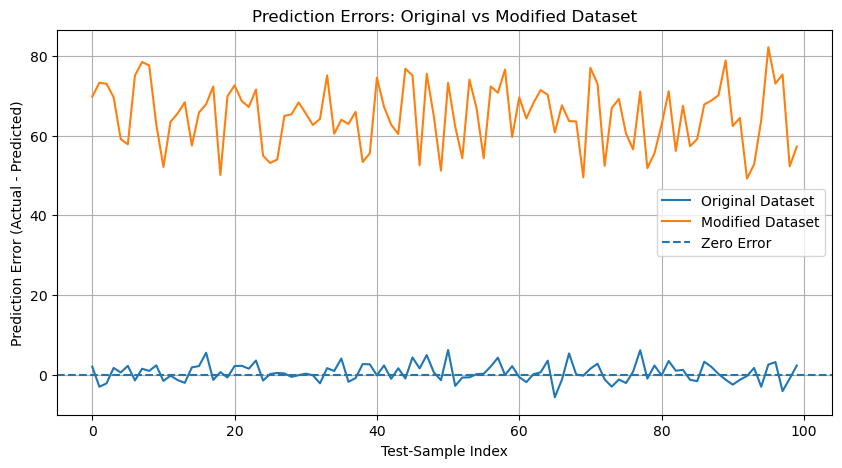

In [55]:
# ----------------------------------------------------------
# Prediction Error Plot
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    original_error,
    label="Original Dataset"
)

plt.plot(
    modified_error,
    label="Modified Dataset"
)

plt.axhline(
    y=0,
    linestyle="--",
    label="Zero Error"
)

plt.title(
    "Prediction Errors: Original vs Modified Dataset"
)

plt.xlabel("Test-Sample Index")

plt.ylabel(
    "Prediction Error (Actual - Predicted)"
)

plt.legend()

plt.grid(True)

plt.show()



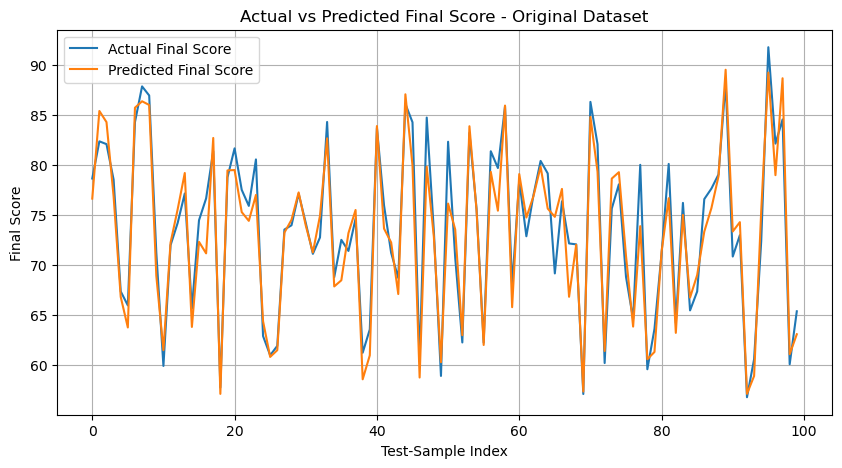

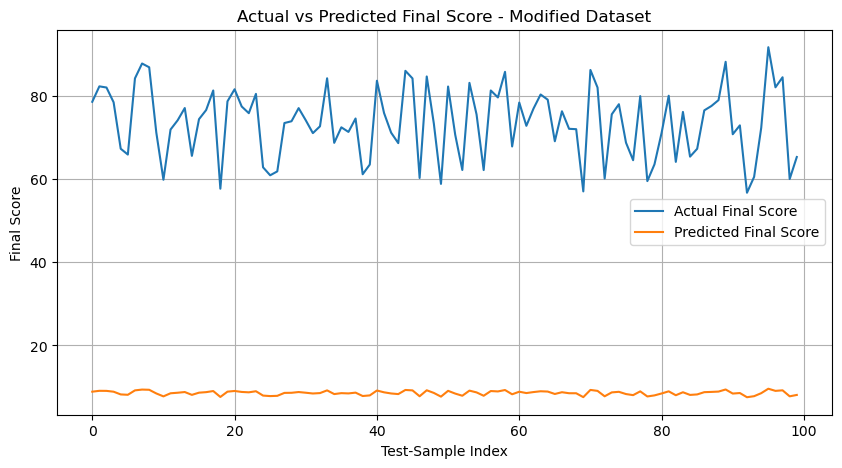

In [56]:
# ==========================================================
# (d) Actual vs Predicted - Original Dataset
# ==========================================================

plt.figure(figsize=(10, 5))

plt.plot(
    yo_test.values,
    label="Actual Final Score"
)

plt.plot(
    yo_pred,
    label="Predicted Final Score"
)

plt.title(
    "Actual vs Predicted Final Score - Original Dataset"
)

plt.xlabel("Test-Sample Index")

plt.ylabel("Final Score")

plt.legend()

plt.grid(True)

plt.show()


# ==========================================================
# (d) Actual vs Predicted - Modified Dataset
# ==========================================================

plt.figure(figsize=(10, 5))

plt.plot(
    ym_test.values,
    label="Actual Final Score"
)

plt.plot(
    ym_pred,
    label="Predicted Final Score"
)

plt.title(
    "Actual vs Predicted Final Score - Modified Dataset"
)

plt.xlabel("Test-Sample Index")

plt.ylabel("Final Score")

plt.legend()

plt.grid(True)

plt.show()

In [57]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

degrees = [2, 3, 4]

train_mse = []
test_mse = []
train_r2 = []
test_r2 = []

predictions = {}

for degree in degrees:

    # Create polynomial features
    poly = PolynomialFeatures(degree=degree)

    Xo_train_poly = poly.fit_transform(Xo_train)
    Xo_test_poly = poly.transform(Xo_test)

    # Create and train model
    model = LinearRegression()
    model.fit(Xo_train_poly, yo_train)

    # Predictions
    yo_train_pred = model.predict(Xo_train_poly)
    yo_test_pred = model.predict(Xo_test_poly)

    # Store test predictions
    predictions[degree] = yo_test_pred

    # Calculate MSE
    train_mse.append(
        mean_squared_error(yo_train, yo_train_pred)
    )

    test_mse.append(
        mean_squared_error(yo_test, yo_test_pred)
    )

    # Calculate R²
    train_r2.append(
        r2_score(yo_train, yo_train_pred)
    )

    test_r2.append(
        r2_score(yo_test, yo_test_pred)
    )


# Display results
results = pd.DataFrame({
    "Degree": degrees,
    "Training MSE": train_mse,
    "Testing MSE": test_mse,
    "Training R2": train_r2,
    "Testing R2": test_r2
})

print(results)

   Degree  Training MSE  Testing MSE  Training R2  Testing R2
0       2      4.243676     5.507801     0.942241    0.922232
1       3      3.532199     5.874623     0.951925    0.917053
2       4      2.139892    15.132713     0.970875    0.786333


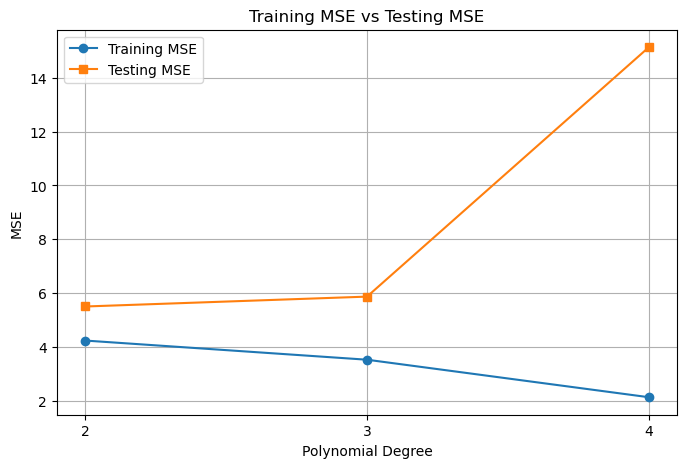

In [58]:
plt.figure(figsize=(8, 5))

plt.plot(
    degrees,
    train_mse,
    marker='o',
    label='Training MSE'
)

plt.plot(
    degrees,
    test_mse,
    marker='s',
    label='Testing MSE'
)

plt.xlabel("Polynomial Degree")
plt.ylabel("MSE")
plt.title("Training MSE vs Testing MSE")
plt.xticks(degrees)
plt.legend()
plt.grid(True)

plt.show()

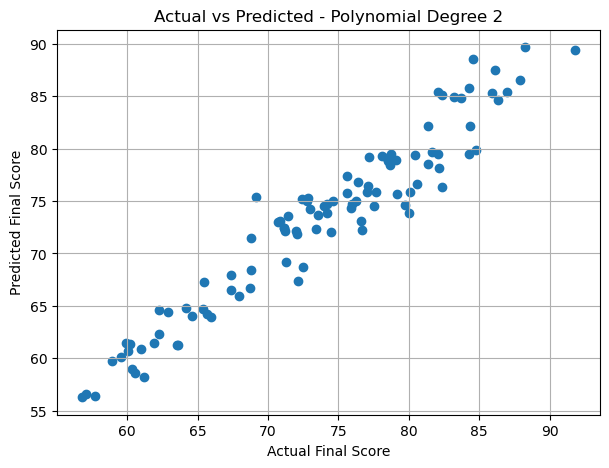

In [60]:
plt.figure(figsize=(7, 5))

plt.scatter(
    yo_test,
    predictions[2]
)

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")
plt.title("Actual vs Predicted - Polynomial Degree 2")

plt.grid(True)
plt.show()

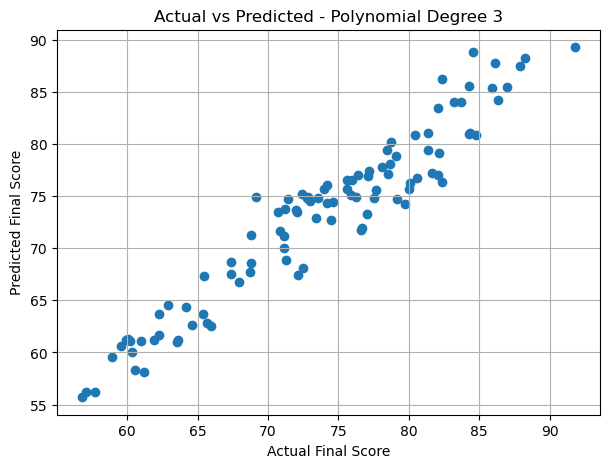

In [61]:
plt.figure(figsize=(7, 5))

plt.scatter(
    yo_test,
    predictions[3]
)

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")
plt.title("Actual vs Predicted - Polynomial Degree 3")

plt.grid(True)
plt.show()

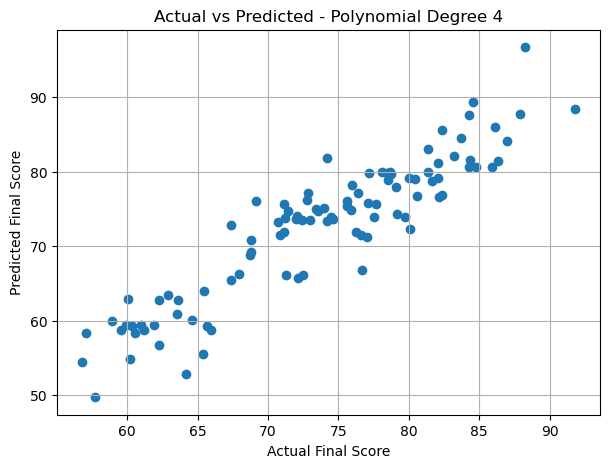

In [62]:
plt.figure(figsize=(7, 5))

plt.scatter(
    yo_test,
    predictions[4]
)

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")
plt.title("Actual vs Predicted - Polynomial Degree 4")

plt.grid(True)
plt.show()

In [63]:
best_degree = degrees[test_mse.index(min(test_mse))]

print("Best Polynomial Degree:", best_degree)
print("Lowest Testing MSE:", min(test_mse))
print("Testing R2:", test_r2[test_mse.index(min(test_mse))])

Best Polynomial Degree: 2
Lowest Testing MSE: 5.5078012806938945
Testing R2: 0.9222322061488637
